In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

sns.set_theme(style='whitegrid')


In [2]:
orders = pd.read_csv('data/olist_orders_dataset.csv')
items = pd.read_csv('data/olist_order_items_dataset.csv')
products = pd.read_csv('data/olist_products_dataset.csv')
customers = pd.read_csv('data/olist_customers_dataset.csv')
sellers = pd.read_csv('data/olist_sellers_dataset.csv')
payments = pd.read_csv('data/olist_order_payments_dataset.csv')

orders = orders[(orders['order_status'] == 'delivered') & orders['order_delivered_customer_date'].notnull()].copy()

orders['purchase_time'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['delivery_time'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['approved_time'] = pd.to_datetime(orders['order_approved_at'])

orders['delivery_days'] = (orders['delivery_time'] - orders['purchase_time']).dt.total_seconds() / 86400.0
orders = orders[(orders['delivery_days'] >= 0.5) & (orders['delivery_days'] <= 60.0)].copy()

orders[['order_id', 'delivery_days']].head()


,order_id,delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877


In [3]:
products['volume_cm3'] = products['product_length_cm'] * products['product_height_cm'] * products['product_width_cm']
items_p = items.merge(products, on='product_id', how='left')

order_items = items_p.groupby('order_id').agg(
    items_count=('order_item_id', 'count'),
    price=('price', 'sum'),
    freight=('freight_value', 'sum'),
    weight_g=('product_weight_g', 'sum'),
    volume_cm3=('volume_cm3', 'sum'),
    seller_id=('seller_id', 'first')
).reset_index()

pay_agg = payments.groupby('order_id').agg(
    installments=('payment_installments', 'max')
).reset_index()

df = orders.merge(order_items, on='order_id', how='inner')
df = df.merge(pay_agg, on='order_id', how='left')
df = df.merge(customers[['customer_id', 'customer_state']], on='customer_id', how='left')
df = df.merge(sellers[['seller_id', 'seller_state']], on='seller_id', how='left')

df['approval_hours'] = (df['approved_time'] - df['purchase_time']).dt.total_seconds() / 3600.0
df['approval_hours'] = df['approval_hours'].fillna(df['approval_hours'].median()).clip(0, 168)

df['weight_kg'] = df['weight_g'].fillna(df['weight_g'].median()) / 1000.0
df['volume_dm3'] = df['volume_cm3'].fillna(df['volume_cm3'].median()) / 1000.0
df['installments'] = df['installments'].fillna(1)
df['same_state'] = (df['customer_state'] == df['seller_state']).astype(int)

df['hour'] = df['purchase_time'].dt.hour
df['weekday'] = df['purchase_time'].dt.day_of_week
df['month'] = df['purchase_time'].dt.month

features = ['freight', 'price', 'weight_kg', 'volume_dm3', 'items_count', 'same_state', 'approval_hours', 'installments', 'hour', 'weekday', 'month']
df[['delivery_days'] + features].head()


,delivery_days,freight,price,weight_kg,volume_dm3,items_count,same_state,approval_hours,installments,hour,weekday,month
0,8.436574,8.72,29.99,0.50,1.976,1,1,0.178333,1.0,10,0,10
1,13.782037,22.76,118.70,0.40,4.693,1,0,30.713889,1.0,20,1,7
2,9.394213,19.22,159.90,0.42,9.576,1,0,0.276111,3.0,8,2,8
3,13.208750,27.20,45.00,0.45,6.000,1,0,0.298056,1.0,19,5,11
4,2.873877,8.72,19.90,0.25,11.475,1,1,1.030556,1.0,21,1,2


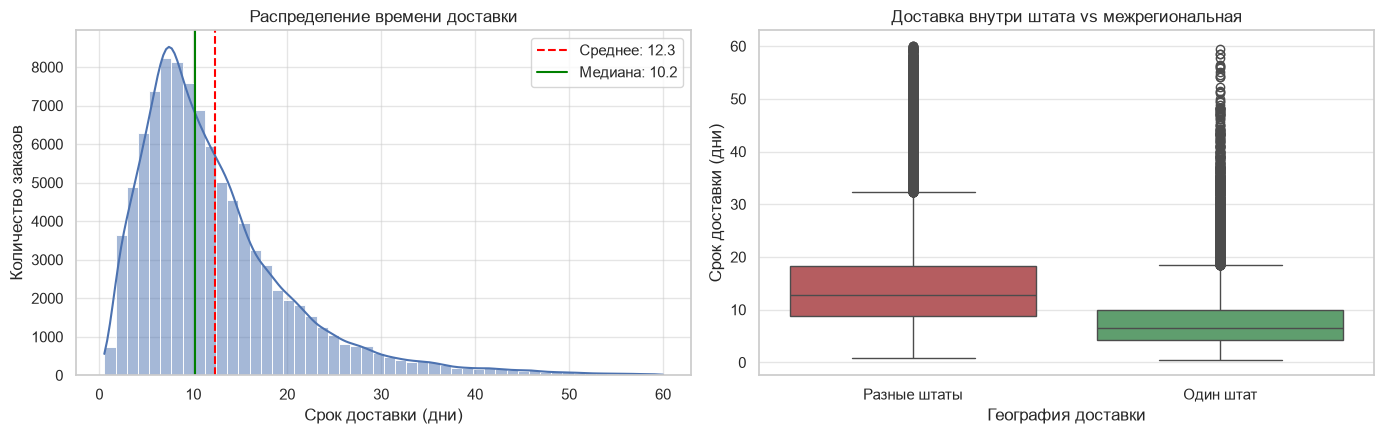

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(df['delivery_days'], kde=True, bins=50, ax=axes[0], color='#4C72B0')
axes[0].axvline(df['delivery_days'].mean(), color='red', linestyle='--', label=f"Среднее: {df['delivery_days'].mean():.1f}")
axes[0].axvline(df['delivery_days'].median(), color='green', label=f"Медиана: {df['delivery_days'].median():.1f}")
axes[0].set_xlabel('Срок доставки (дни)')
axes[0].set_ylabel('Количество заказов')
axes[0].set_title('Распределение времени доставки')
axes[0].legend()

sns.boxplot(data=df, x='same_state', y='delivery_days', ax=axes[1], hue='same_state', palette=['#C44E52', '#55A868'], legend=False)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Разные штаты', 'Один штат'])
axes[1].set_xlabel('География доставки')
axes[1].set_ylabel('Срок доставки (дни)')
axes[1].set_title('Доставка внутри штата vs межрегиональная')

plt.tight_layout()
plt.show()


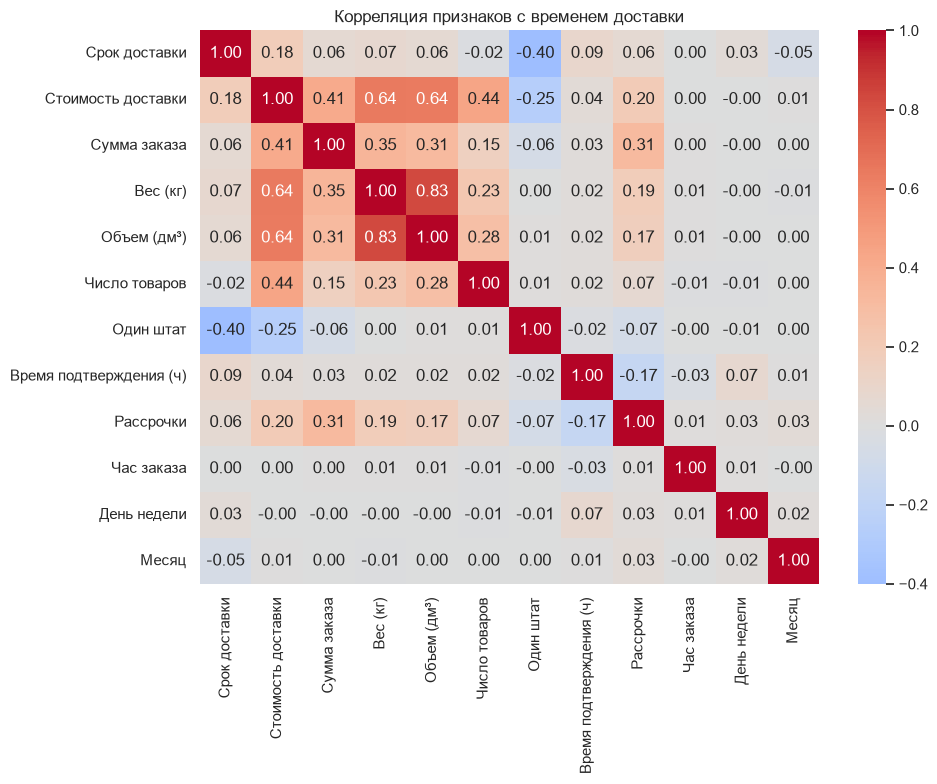

Обучающая выборка: 76931 Тестовая выборка: 19233


In [6]:
feature_names_ru = [
    'Срок доставки', 'Стоимость доставки', 'Сумма заказа', 'Вес (кг)',
    'Объем (дм³)', 'Число товаров', 'Один штат', 'Время подтверждения (ч)',
    'Рассрочки', 'Час заказа', 'День недели', 'Месяц'
]

corr_matrix = df[['delivery_days'] + features].corr()
corr_matrix.columns = feature_names_ru
corr_matrix.index = feature_names_ru

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляция признаков с временем доставки')
plt.tight_layout()
plt.show()

X = df[features]
y = df['delivery_days']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print('Обучающая выборка:', X_train.shape[0], 'Тестовая выборка:', X_test.shape[0])


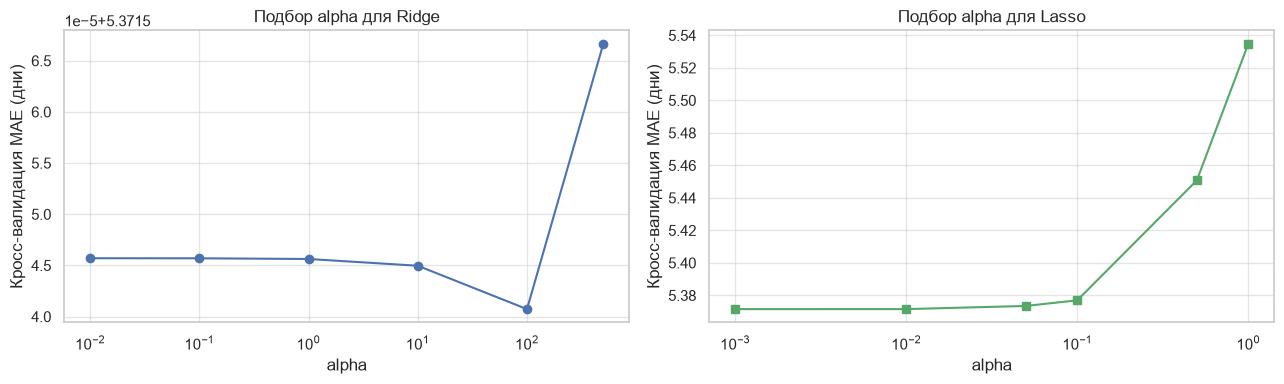

Лучший alpha для Ridge: 100.0 | MAE: 5.3715
Лучший alpha для Lasso: 0.001 | MAE: 5.3715


In [7]:
alphas = [0.01, 0.1, 1.0, 10.0, 100.0, 500.0]
kf = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_scores = []
for a in alphas:
    m = Ridge(alpha=a)
    score = -cross_val_score(m, X_train_sc, y_train, scoring='neg_mean_absolute_error', cv=kf, n_jobs=-1).mean()
    ridge_scores.append(score)

lasso_alphas = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0]
lasso_scores = []
for a in lasso_alphas:
    m = Lasso(alpha=a, max_iter=1000, tol=1e-3, random_state=42)
    score = -cross_val_score(m, X_train_sc, y_train, scoring='neg_mean_absolute_error', cv=kf, n_jobs=-1).mean()
    lasso_scores.append(score)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(alphas, ridge_scores, marker='o', color='#4C72B0')
axes[0].set_xscale('log')
axes[0].set_title('Подбор alpha для Ridge')
axes[0].set_xlabel('alpha')
axes[0].set_ylabel('Кросс-валидация MAE (дни)')
axes[0].grid(True)

axes[1].plot(lasso_alphas, lasso_scores, marker='s', color='#55A868')
axes[1].set_xscale('log')
axes[1].set_title('Подбор alpha для Lasso')
axes[1].set_xlabel('alpha')
axes[1].set_ylabel('Кросс-валидация MAE (дни)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

best_ridge_alpha = alphas[ridge_scores.index(min(ridge_scores))]
best_lasso_alpha = lasso_alphas[lasso_scores.index(min(lasso_scores))]
print('Лучший alpha для Ridge:', best_ridge_alpha, '| MAE:', round(min(ridge_scores), 4))
print('Лучший alpha для Lasso:', best_lasso_alpha, '| MAE:', round(min(lasso_scores), 4))


,Модель,MAE,RMSE,R2
0,Линейная регрессия,5.425580,7.695834,0.179392
1,Ridge (alpha=100.0),5.425637,7.695855,0.179388
2,Lasso (alpha=0.001),5.425558,7.695793,0.179401


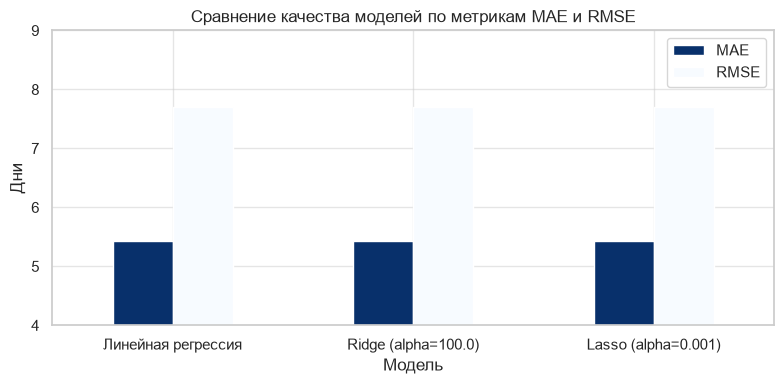

In [9]:
models = {
    'Линейная регрессия': LinearRegression(),
    f'Ridge (alpha={best_ridge_alpha})': Ridge(alpha=best_ridge_alpha),
    f'Lasso (alpha={best_lasso_alpha})': Lasso(alpha=best_lasso_alpha, max_iter=1000, tol=1e-3, random_state=42)
}

res = []
for name, m in models.items():
    m.fit(X_train_sc, y_train)
    y_pred = m.predict(X_test_sc)
    res.append({
        'Модель': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': root_mean_squared_error(y_test, y_pred),
        'R2': r2_score(y_test, y_pred)
    })

res_df = pd.DataFrame(res)
display(res_df)

fig, ax = plt.subplots(figsize=(8, 4))
res_df.plot(x='Модель', y=['MAE', 'RMSE'], kind='bar', ax=ax, colormap='Blues_r')
ax.set_ylabel('Дни')
ax.set_title('Сравнение качества моделей по метрикам MAE и RMSE')
ax.set_xticklabels(res_df['Модель'], rotation=0)
ax.set_ylim(4, 9)
plt.tight_layout()
plt.show()


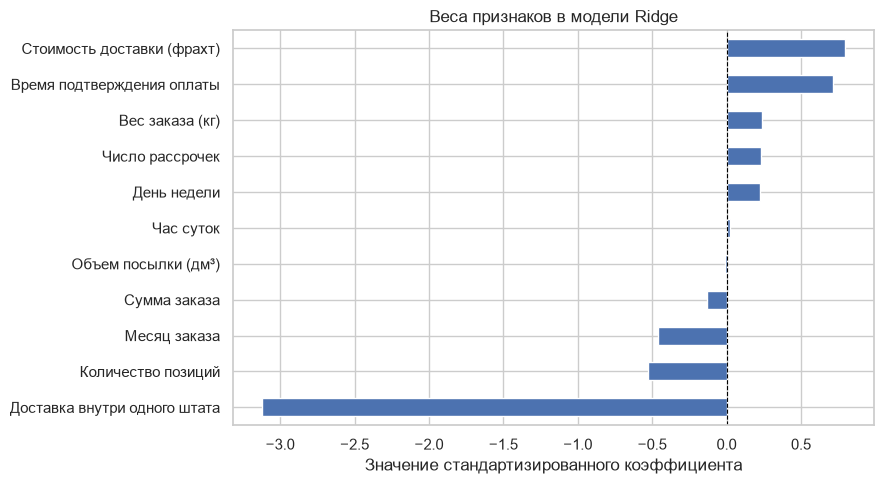

In [8]:
best_model = models[f'Ridge (alpha={best_ridge_alpha})']

labels_dict = {
    'same_state': 'Доставка внутри одного штата',
    'freight': 'Стоимость доставки (фрахт)',
    'approval_hours': 'Время подтверждения оплаты',
    'weight_kg': 'Вес заказа (кг)',
    'volume_dm3': 'Объем посылки (дм³)',
    'month': 'Месяц заказа',
    'price': 'Сумма заказа',
    'installments': 'Число рассрочек',
    'weekday': 'День недели',
    'items_count': 'Количество позиций',
    'hour': 'Час суток'
}

coef_series = pd.Series(best_model.coef_, index=[labels_dict[f] for f in features]).sort_values()

plt.figure(figsize=(9, 5))
coef_series.plot(kind='barh', color='#4C72B0')
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Веса признаков в модели Ridge')
plt.xlabel('Значение стандартизированного коэффициента')
plt.tight_layout()
plt.show()


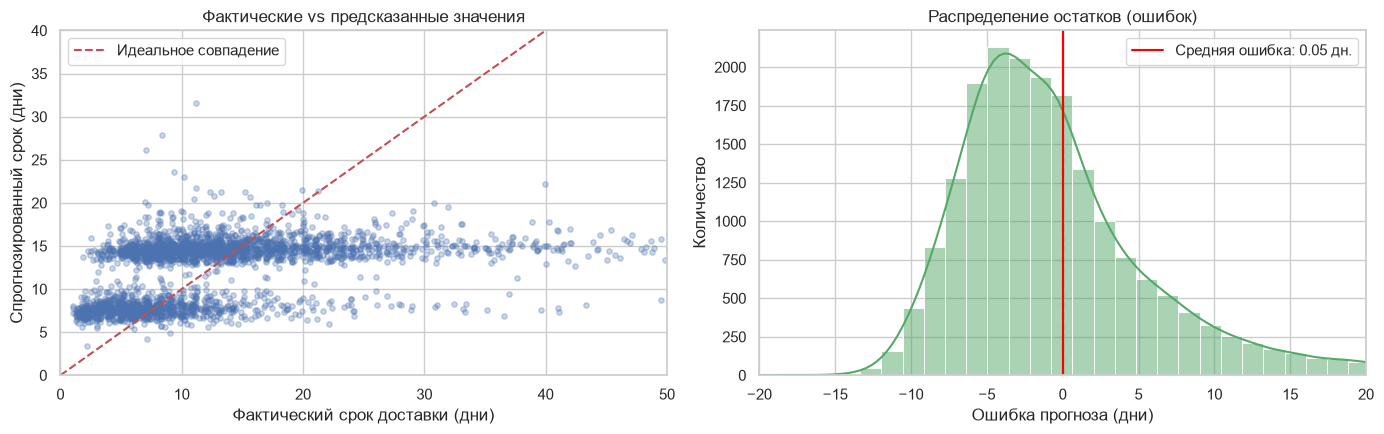

,Фактический срок,Прогноз,Ошибка
0,20.01,14.74,5.28
1,11.01,13.41,-2.40
2,6.21,8.39,-2.19
3,11.12,13.75,-2.63
4,8.87,13.93,-5.06
5,10.27,15.61,-5.35
6,12.81,18.71,-5.90
7,8.01,8.37,-0.36
8,9.04,15.89,-6.85
9,4.41,7.76,-3.35


In [9]:
y_pred_best = best_model.predict(X_test_sc)
res = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sample_idx = np.random.choice(len(y_test), 3000, replace=False)
axes[0].scatter(y_test.values[sample_idx], y_pred_best[sample_idx], alpha=0.3, s=15, color='#4C72B0')
axes[0].plot([0, 50], [0, 50], 'r--', label='Идеальное совпадение')
axes[0].set_xlim(0, 50)
axes[0].set_ylim(0, 40)
axes[0].set_xlabel('Фактический срок доставки (дни)')
axes[0].set_ylabel('Спрогнозированный срок (дни)')
axes[0].set_title('Фактические vs предсказанные значения')
axes[0].legend()

sns.histplot(res, kde=True, bins=50, ax=axes[1], color='#55A868')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].axvline(res.mean(), color='red', label=f"Средняя ошибка: {res.mean():.2f} дн.")
axes[1].set_xlim(-20, 20)
axes[1].set_xlabel('Ошибка прогноза (дни)')
axes[1].set_ylabel('Количество')
axes[1].set_title('Распределение остатков (ошибок)')
axes[1].legend()

plt.tight_layout()
plt.show()

pred_sample = pd.DataFrame({
    'Фактический срок': y_test.values[:10],
    'Прогноз': y_pred_best[:10],
    'Ошибка': res.values[:10]
})
pred_sample.round(2)
